# Logistic Regression (Multiclass): Capstone

**Task:** single-label multiclass classification. The target has several categories, and each row gets exactly one predicted category.

Structure follows [docs/logistic_regression_notebook_structure.md](../docs/logistic_regression_notebook_structure.md) (see its Multiclass section).
Companion notebook on the same dataset: [linear_regression.ipynb](linear_regression.ipynb).

**Rule of thumb:** EDA (check class balance) → clean and encode → engineer → check assumptions (now covering the encoded columns) → clean again → scale → stratified split → baseline → train → evaluate with macro metrics, the confusion matrix, one-vs-rest ROC curves and prediction confidence → interpret the per-class coefficients.

# Setup

## Environment (local or Colab)

Makes the repo's `utils` package importable.
- **Local:** works from `capstone/` without anything extra (the repo root is added to `sys.path`). `pip install -e .` from the repo root also works.
- **Colab:** set `REPO_URL` below to clone the repo, or upload the `utils/` folder next to this notebook. Upload the dataset too, or point `DATA_FILE` at it.

In [110]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = ""  # Colab only, e.g. "https://github.com/<user>/devML.git"

if IN_COLAB and REPO_URL and not Path("devML").exists():
    import subprocess
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)

# Find the folder that contains utils/ and put it on the import path
for candidate in (Path.cwd(), Path.cwd().parent, Path.cwd() / "devML"):
    if (candidate / "utils").is_dir():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break
else:
    print("utils/ not found: clone the repo or upload the utils folder.")

print(f"Colab: {IN_COLAB} | cwd: {Path.cwd()}")

Colab: False | cwd: /Users/aricode0/devML/capstone


## Imports

In [111]:
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
)

## Reproducibility

`RANDOM_STATE` is passed to sklearn (split, model, baseline). `np.random.seed` covers any direct `np.random.*` calls.

In [112]:
RANDOM_STATE: int = 42
np.random.seed(RANDOM_STATE)

## Utils

Imported from the repo's `utils` package rather than redefined here.

In [113]:
from utils.base import load_dataset
from utils.eda import (
    check_columns_for_inf,
    check_columns_for_na,
    check_dataset_size_and_shape,
    dummy_error_to_stop_runs,
    show_columns_with_missing_values,
)
from utils.tests import (
    test_no_inf_columns,
    test_no_missing_values,
    test_only_numeric_columns,
    test_train_test_split_ratio,
)
from utils.preprocessing import apply_iqr_outlier_removal, remove_rows_with_inf
from utils.plots import plot_boxplots_of_numeric_features
from utils.classification import evaluate_multiclass, plot_confusion_matrix

# Load Dataset

Same dataset as `linear_regression.ipynb`. `TARGET` is a categorical column with two or more classes; each row has exactly one.

In [114]:
DATA_FILE: str = "dataset_full.csv"  # path relative to this notebook
TARGET: str = "domain_context"  # single-label multiclass target column

df = load_dataset(DATA_FILE)
df.head()

,source,target,source_length,target_length,readability_score,complexity_level,synthetic_template,domain_context,is_paraphrased,generation_method,quality_flag
0,"Because of data-driven methods, the algorithm ...",": Because of data-driven methods, the algorith...",15,16,22.410000,Medium,T4,Education,True,t5-base,Low
1,"Considering the impact of data preprocessing, ...",: Considering the impact of data preprocessing...,13,14,-40.636923,Low,T2,AI,False,t5-base,Low
2,"Because of data preprocessing, the algorithm i...",": Because of data preprocessing, the algorithm...",16,17,0.245000,Medium,T5,AI,False,t5-base,High
3,"Despite the fact that data preprocessing, rene...","Despite the fact that data preprocessing, rene...",17,17,0.474118,Medium,T1,Climate,False,t5-base,Medium
4,"Because of global warming, the algorithm is ca...",": Because of global warming, the algorithm is ...",15,31,28.050000,Medium,T5,Education,False,t5-base,Low


# Exploratory Data Analysis (EDA)

## General

In [115]:
check_dataset_size_and_shape(df)
df.info()
df.describe(include="all").T

Number of rows: 1563
Dataset shape: (1563, 11)
Number of rows (alternative): 1563
<class 'pandas.DataFrame'>
RangeIndex: 1563 entries, 0 to 1562
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   source              1563 non-null   str    
 1   target              1563 non-null   str    
 2   source_length       1563 non-null   int64  
 3   target_length       1563 non-null   int64  
 4   readability_score   1563 non-null   float64
 5   complexity_level    1563 non-null   str    
 6   synthetic_template  1563 non-null   str    
 7   domain_context      1563 non-null   str    
 8   is_paraphrased      1563 non-null   bool   
 9   generation_method   1563 non-null   str    
 10  quality_flag        1563 non-null   str    
dtypes: bool(1), float64(1), int64(2), str(7)
memory usage: 123.8 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
source,1563,1346,While global warming offers numerous advantage...,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target,1563,1269,,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_length,1563.0,NaN,NaN,NaN,14.837492,1.672387,12.0,13.0,15.0,16.0,21.0
target_length,1563.0,NaN,NaN,NaN,18.06334,11.066055,0.0,14.0,16.0,18.0,74.0
readability_score,1563.0,NaN,NaN,NaN,14.503394,21.795486,-50.91,-0.15,16.1075,29.467857,68.9825
complexity_level,1563,2,Medium,827,NaN,NaN,NaN,NaN,NaN,NaN,NaN
synthetic_template,1563,5,T1,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
domain_context,1563,5,AI,325,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_paraphrased,1563,2,True,805,NaN,NaN,NaN,NaN,NaN,NaN,NaN
generation_method,1563,1,t5-base,1563,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Missing Data (NaN, nulls, inf)

In [116]:
missing_cols = show_columns_with_missing_values(df)
columns_with_inf = check_columns_for_inf(df)

Columns with missing values:
Series([], dtype: int64)
Positive inf counts:
source_length        0
target_length        0
readability_score    0
dtype: int64

Negative inf counts:
source_length        0
target_length        0
readability_score    0
dtype: int64
Columns with inf values: []


## Class Balance

Chance level for accuracy is roughly `1 / n_classes` when classes are balanced. If some classes are much rarer than others, use `class_weight="balanced"` and lean on macro-averaged metrics rather than accuracy.

The tests check that this is a valid single-label target: one value per row, at least two classes, and enough rows in every class for a stratified split.

In [117]:
class_counts = df[TARGET].value_counts()
n_classes = class_counts.size
print(pd.DataFrame({"count": class_counts, "share": (class_counts / len(df)).round(3)}))
print(f"{n_classes} classes | chance accuracy ≈ {1 / n_classes:.3f} | majority-class accuracy = {class_counts.iloc[0] / len(df):.3f}")

MIN_ROWS_PER_CLASS: int = 10  # needed so every class appears in both train and test

assert df[TARGET].notna().all(), f"{TARGET} has {df[TARGET].isna().sum()} missing labels"
assert n_classes >= 2, f"{TARGET} needs at least 2 classes, found {n_classes}"
assert n_classes < len(df) / 2, f"{TARGET} has {n_classes} unique values for {len(df)} rows; is it an ID or free text?"
assert class_counts.min() >= MIN_ROWS_PER_CLASS, (
    f"Classes with fewer than {MIN_ROWS_PER_CLASS} rows: {class_counts[class_counts < MIN_ROWS_PER_CLASS].to_dict()}"
)

                count  share
domain_context              
AI                325  0.208
Education         323  0.207
Translation       317  0.203
NLP               309  0.198
Climate           289  0.185
5 classes | chance accuracy ≈ 0.200 | majority-class accuracy = 0.208


# Preprocessing

## Dropping

Drop columns that can't be used as model inputs: free text, IDs, and columns with a single value.

In [118]:
KEEP_COLS: List[str] = ["complexity_level", "domain_context", "quality_flag"]

DROP_COLS = [c for c in df.columns if c not in KEEP_COLS]
print("Dropping:", DROP_COLS)
df = df.drop(columns=DROP_COLS)

Dropping: ['source', 'target', 'source_length', 'target_length', 'readability_score', 'synthetic_template', 'is_paraphrased', 'generation_method']


## Imputing

In [119]:
# TODO: fill missing values if any, e.g. df[col] = df[col].fillna(df[col].median())

## Encoding

Done here, before the 2nd EDA, so the encoded columns are numeric and get picked up by the multicollinearity and infinite-value checks.

One-hot encode categorical **features** (`drop_first=True` avoids a redundant column per category). The **target** stays as its class labels: sklearn's `LogisticRegression` handles string labels directly, and keeping them makes reports and plots readable.

`CONTINUOUS_COLS` (numeric before encoding) and `ENCODED_COLS` (new 0/1 columns) are kept separately, because outlier checks and IQR removal only make sense for continuous values. On a 0/1 column, IQR would mark the less common value as an outlier and drop those rows.

In [120]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
columns_to_encode = KEEP_COLS


for col in columns_to_encode:
    df[f'{col}_encoded'] = le.fit_transform(df[col])
    if col == TARGET:
        # le is refit per column, so save the target's code -> label mapping now
        TARGET_LABELS: Dict[int, str] = dict(enumerate(le.classes_))

print("Target mapping:", TARGET_LABELS)

# df['satisfaction_encoded'] = le.fit_transform(df['satisfaction'])
# Map: unsatisfied=0, satisfied=1 (alphabetical order by default)
df.info()
df.head()

Target mapping: {0: 'AI', 1: 'Climate', 2: 'Education', 3: 'NLP', 4: 'Translation'}
<class 'pandas.DataFrame'>
RangeIndex: 1563 entries, 0 to 1562
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   complexity_level          1563 non-null   str  
 1   domain_context            1563 non-null   str  
 2   quality_flag              1563 non-null   str  
 3   complexity_level_encoded  1563 non-null   int64
 4   domain_context_encoded    1563 non-null   int64
 5   quality_flag_encoded      1563 non-null   int64
dtypes: int64(3), str(3)
memory usage: 73.4 KB


,complexity_level,domain_context,quality_flag,complexity_level_encoded,domain_context_encoded,quality_flag_encoded
0,Medium,Education,Low,1,2,1
1,Low,AI,Low,0,0,1
2,Medium,AI,High,1,0,0
3,Medium,Climate,Medium,1,1,2
4,Medium,Education,Low,1,2,1


In [121]:
# get a general idea of the value counts for each column
df.value_counts()

complexity_level  domain_context  quality_flag  complexity_level_encoded  domain_context_encoded  quality_flag_encoded
Medium            AI              High          1                         0                       0                       75
                  Translation     High          1                         4                       0                       64
                  Education       Medium        1                         2                       2                       62
                  Climate         High          1                         1                       0                       62
Low               NLP             Low           0                         3                       1                       61
Medium            NLP             Low           1                         3                       1                       59
                                  High          1                         3                       0                       57
      

## Dropping

In [122]:
DROP_COLS: List[str] = ["complexity_level", "domain_context", "quality_flag"]

print("Dropping:", DROP_COLS)
df = df.drop(columns=DROP_COLS)

# The original target column was dropped; use its encoded version from here on
TARGET = "domain_context_encoded"
df.info()

Dropping: ['complexity_level', 'domain_context', 'quality_flag']
<class 'pandas.DataFrame'>
RangeIndex: 1563 entries, 0 to 1562
Data columns (total 3 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   complexity_level_encoded  1563 non-null   int64
 1   domain_context_encoded    1563 non-null   int64
 2   quality_flag_encoded      1563 non-null   int64
dtypes: int64(3)
memory usage: 36.8 KB


# Feature Engineering

Group new features by domain, one sub-header each. Categorical columns are already one-hot encoded at this point, so build from the numeric or encoded columns, and add any new continuous feature to `CONTINUOUS_COLS`.

                  count      mean       std       min       25%       50%  \
sentiment_score  1563.0  0.499691  0.290558  0.000519  0.241171  0.493290   
emotion_score    1563.0  0.499862  0.289012  0.000568  0.246991  0.497026   

                      75%       max  
sentiment_score  0.758255  0.999422  
emotion_score    0.753931  0.999765  


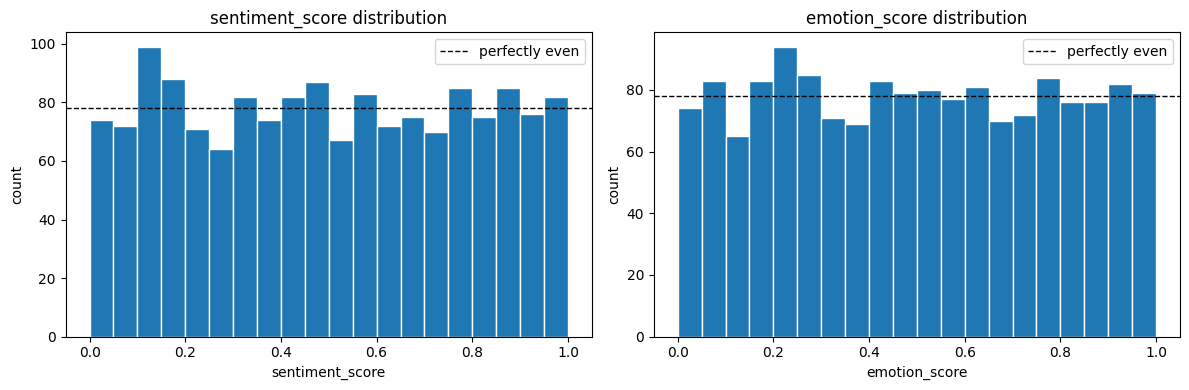

In [123]:
# Synthetic scores: uniform random in [0, 1), one value per row (roughly even distribution)
rng = np.random.default_rng(RANDOM_STATE)
NEW_FEATURES: List[str] = ["sentiment_score", "emotion_score"]
for col in NEW_FEATURES:
    df[col] = rng.uniform(0.0, 1.0, size=len(df))

# Register as continuous features (CONTINUOUS_COLS isn't defined earlier yet, so start it if missing)
CONTINUOUS_COLS = globals().get("CONTINUOUS_COLS", [])
CONTINUOUS_COLS += [c for c in NEW_FEATURES if c not in CONTINUOUS_COLS]

print(df[NEW_FEATURES].describe().T)

# Distribution of the new features
fig, axes = plt.subplots(1, len(NEW_FEATURES), figsize=(12, 4))
for ax, col in zip(axes, NEW_FEATURES):
    ax.hist(df[col], bins=20, range=(0, 1), edgecolor="white")
    ax.axhline(len(df) / 20, color="black", linestyle="--", linewidth=1, label="perfectly even")
    ax.set_title(f"{col} distribution")
    ax.set_xlabel(col)
    ax.set_ylabel("count")
    ax.legend()
plt.tight_layout()
plt.show()

# 2nd EDA: Assumption Checks

Logistic regression assumes the **log-odds** of the target are roughly linear in the features, little collinearity, and independent rows. It does not need the features to be normally distributed.

## Confirm

In [124]:
test_no_missing_values(df, df.columns.tolist())
test_only_numeric_columns(df.drop(columns=[TARGET]))  # every feature is numeric after encoding

All columns are numeric.


## Feature Distributions

Histogram of every numeric column, including the engineered features. Logistic regression doesn't need normal features, but this shows skew, gaps, and how the encoded columns split.

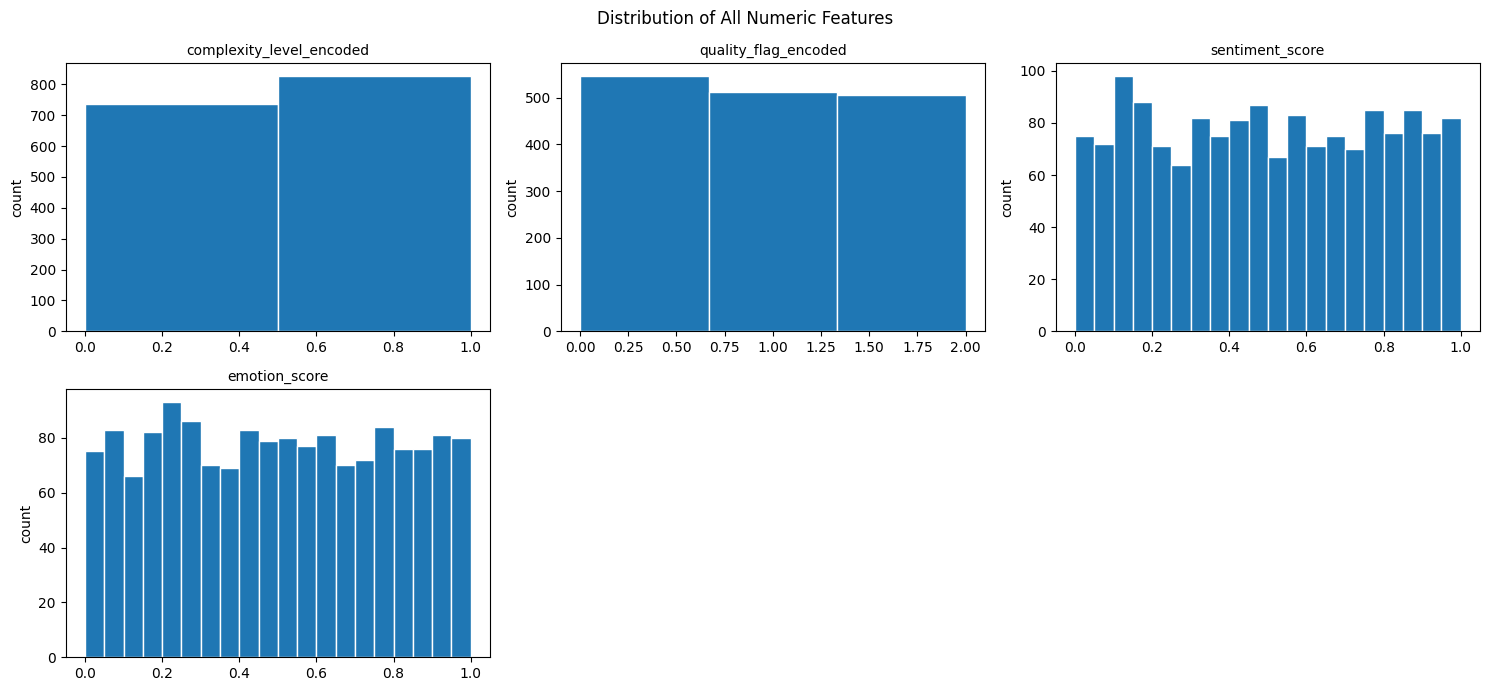

In [125]:
dist_cols = [c for c in df.select_dtypes(include="number").columns if c != TARGET]

n_cols = 3
n_rows = -(-len(dist_cols) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 3.5), squeeze=False)
axes = axes.flatten()
for ax, col in zip(axes, dist_cols):
    n_unique = df[col].nunique()
    bins = n_unique if n_unique <= 10 else 20  # one bar per level for encoded columns
    ax.hist(df[col], bins=bins, edgecolor="white")
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("count")
for ax in axes[len(dist_cols):]:
    ax.set_visible(False)
fig.suptitle("Distribution of All Numeric Features")
plt.tight_layout()
plt.show()

## Multicollinearity

Covers continuous and encoded columns. Dummies from the same original column are always somewhat negatively correlated with each other; that's expected. Watch for high correlation between *different* source columns.

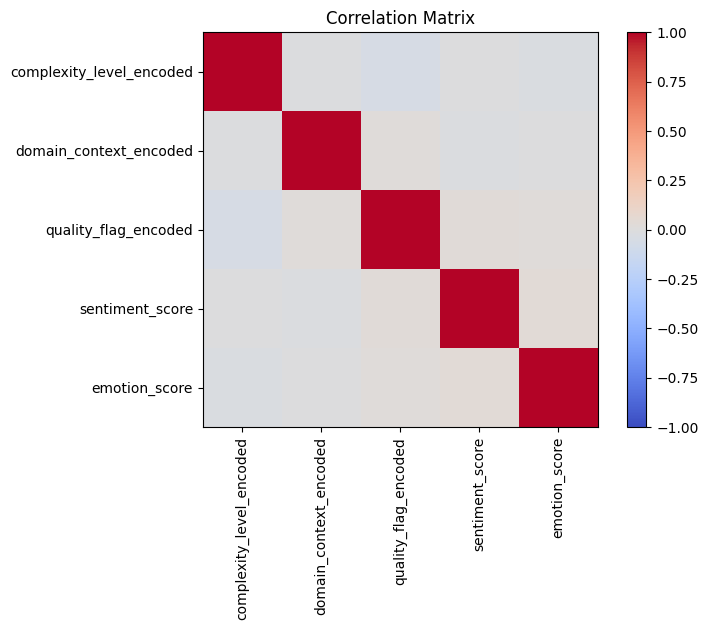

Series([], dtype: float64)

In [126]:
corr = df.select_dtypes(include="number").corr()

size = max(8, 0.45 * len(corr.columns))
fig, ax = plt.subplots(figsize=(size, size * 0.8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)), corr.columns)
fig.colorbar(im)
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()

# Pairs of predictors above a threshold
CORR_THRESHOLD = 0.8
high_corr = (
    corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    .stack()
    .loc[lambda s: s.abs() > CORR_THRESHOLD]
)
high_corr

## Correlation Matrix & Analysis 

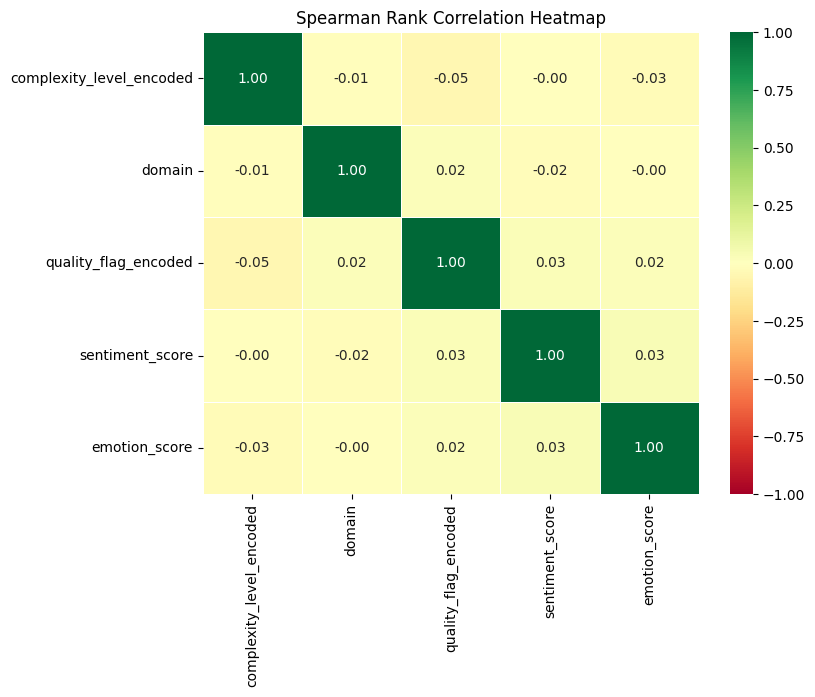

complexity_level_encoded vs domain -> Coef: -0.01, p-value: 0.7189
quality_flag_encoded vs domain -> Coef: 0.02, p-value: 0.4732
sentiment_score vs domain -> Coef: -0.02, p-value: 0.4576
emotion_score vs domain -> Coef: -0.00, p-value: 0.9927


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pointbiserialr

# 1. Load your data (Replace with your actual file path)
# df = pd.read_csv("your_flight_data.csv")

# Quick mock-up dataframe based on your columns 
# data = {
#     'Seat_Comfort':,
#     'Food_Drink':,
#     'Time_Convenient':,
#     'Satisfaction': [1, 0, 1, 0, 0, 1, 1, 0]  # Binary target
# }
# df = pd.DataFrame(data)

# 2. Check Spearman Rank Correlation (Better for 1-5 survey rating scales)
spearman_corr = df.corr(method='spearman')

# [['satisfaction', 'Seat comfort', 'Food and drink', 'Departure/Arrival time convenient']]
# 3. Plot the Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(spearman_corr, annot=True, cmap='RdYlGn', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Spearman Rank Correlation Heatmap")
plt.show()

# 4. Verify Point-Biserial Significance (Testing if correlation is an illusion)
features = [col for col in df.columns if col != TARGET]

for col in features:
  # if df[TARGET].nunique() != 2:
  #   print(f"Skipping {col}: {TARGET} is not binary (n_unique={df[TARGET].nunique()})")
  #   continue
  coef, p_val = pointbiserialr(df[col], df[TARGET])
  print(f"{col} vs {TARGET} -> Coef: {coef:.2f}, p-value: {p_val:.4f}")



## Outliers

Continuous columns only (box plots of 0/1 columns say nothing).

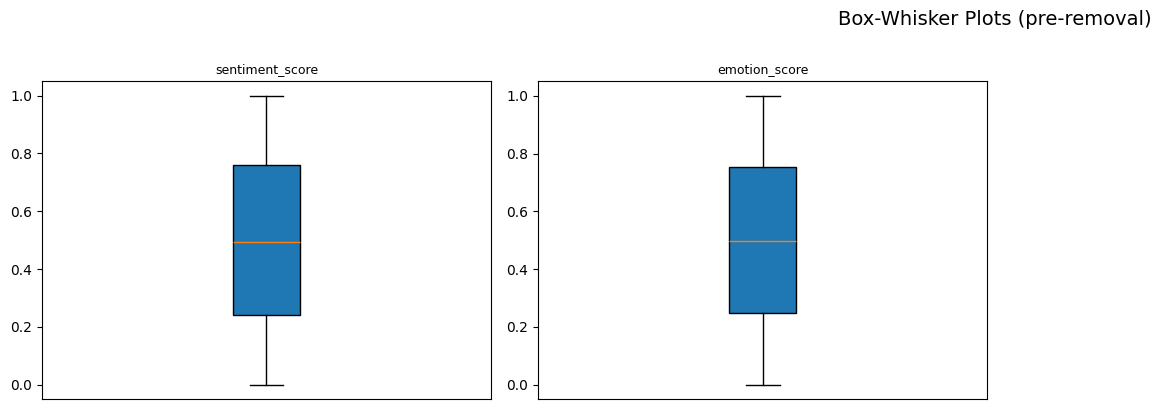

In [127]:
numeric_cols = plot_boxplots_of_numeric_features(df[CONTINUOUS_COLS])

## Features by Class

Features whose values differ between the classes are the likely useful predictors.
- **Continuous columns:** box plot per class.
- **Encoded columns:** share of rows with a 1 in each class. A row that's flat across classes carries little signal.

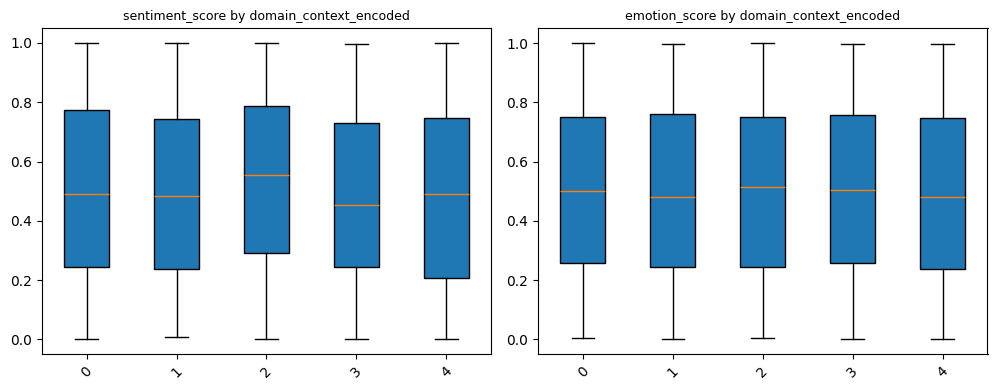

In [128]:
classes = sorted(df[TARGET].unique(), key=str)

n_cols = 4
n_rows = -(-len(CONTINUOUS_COLS) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4), squeeze=False)
axes = axes.flatten()
for i, col in enumerate(CONTINUOUS_COLS):
    axes[i].boxplot([df.loc[df[TARGET] == c, col] for c in classes], patch_artist=True)
    axes[i].set_xticks(range(1, len(classes) + 1), [str(c) for c in classes], rotation=45)
    axes[i].set_title(f"{col} by {TARGET}", fontsize=9)
for j in range(len(CONTINUOUS_COLS), len(axes)):
    axes[j].set_visible(False)
plt.tight_layout()
plt.show()

In [130]:
# encoded_share_by_class = df.groupby(TARGET)[ENCODED_COLS].mean().T.round(3)
# encoded_share_by_class["spread"] = encoded_share_by_class.max(axis=1) - encoded_share_by_class.min(axis=1)
# encoded_share_by_class.sort_values("spread", ascending=False)

## Check Infinites

In [131]:
columns_with_inf = check_columns_for_inf(df)

Positive inf counts:
complexity_level_encoded    0
domain_context_encoded      0
quality_flag_encoded        0
sentiment_score             0
emotion_score               0
dtype: int64

Negative inf counts:
complexity_level_encoded    0
domain_context_encoded      0
quality_flag_encoded        0
sentiment_score             0
emotion_score               0
dtype: int64
Columns with inf values: []


In [132]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1563 entries, 0 to 1562
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   complexity_level_encoded  1563 non-null   int64  
 1   domain_context_encoded    1563 non-null   int64  
 2   quality_flag_encoded      1563 non-null   int64  
 3   sentiment_score           1563 non-null   float64
 4   emotion_score             1563 non-null   float64
dtypes: float64(2), int64(3)
memory usage: 61.2 KB


# 2nd Preprocessing

## Remove Infinites & Extreme Values

In [133]:
df = remove_rows_with_inf(df, columns_with_inf)
test_no_inf_columns(check_columns_for_inf(df))

Positive inf counts:
complexity_level_encoded    0
domain_context_encoded      0
quality_flag_encoded        0
sentiment_score             0
emotion_score               0
dtype: int64

Negative inf counts:
complexity_level_encoded    0
domain_context_encoded      0
quality_flag_encoded        0
sentiment_score             0
emotion_score               0
dtype: int64
Columns with inf values: []


## IQR Outlier Removal (optional)

Less important than for linear regression, since there are no residuals to distort, but extreme values still pull on the coefficients. Applied to the continuous columns only; the encoded 0/1 columns are left out. Check the printed row counts and that the class balance hasn't shifted.

In [134]:
df = apply_iqr_outlier_removal(df, numeric_cols, exclude={TARGET, *ENCODED_COLS})
print(df[TARGET].value_counts(normalize=True).round(3))

Rows removed: 0  (1563 → 1563)
domain_context_encoded
0    0.208
2    0.207
4    0.203
3    0.198
1    0.185
Name: proportion, dtype: float64


## Feature Selection

In [135]:
# TODO: drop one predictor from each highly correlated pair (see high_corr above)
FEATURES: List[str] = [c for c in df.columns if c != TARGET]
print(f"{len(FEATURES)} features: {FEATURES}")

4 features: ['complexity_level_encoded', 'quality_flag_encoded', 'sentiment_score', 'emotion_score']


## Target Rename

In [136]:
# Rename the encoded target column to a clearer name for downstream use
df = df.rename(columns={TARGET: "domain"})
TARGET = "domain"

print(f"Target column renamed to: {TARGET}")
# df[[TARGET]].head()
df[[TARGET]].value_counts()

Target column renamed to: domain


domain
0         325
2         323
4         317
3         309
1         289
Name: count, dtype: int64

## Scaling

`StandardScaler` is put inside the model pipeline (see Training), so it is fit on the training set only and applied to the test set without leakage. Scaled features also make the coefficients comparable.

# Final EDA: Target Distribution

Last check of the target right before training: how many rows fall in each class, shown with readable names.

`TARGET_LABELS` maps each numeric code to its original category (`LABEL_TO_CODE` goes the other way). Use `to_labels(...)` to turn predictions or `model.classes_` back into names during evaluation and interpretation.

            label  count  share
code                           
0              AI    325  0.208
1         Climate    289  0.185
2       Education    323  0.207
3             NLP    309  0.198
4     Translation    317  0.203


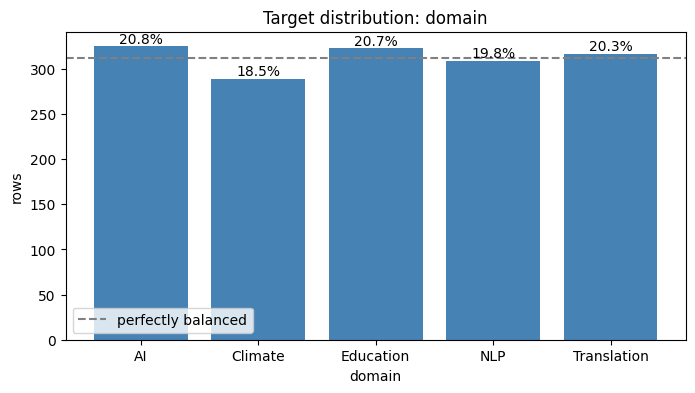

In [138]:
LABEL_TO_CODE: Dict[str, int] = {label: code for code, label in TARGET_LABELS.items()}

def to_labels(codes) -> np.ndarray:
    """Map numeric class codes (e.g. y_pred, model.classes_) to their text labels."""
    return pd.Series(codes).map(TARGET_LABELS).to_numpy()

target_counts = df[TARGET].value_counts().sort_index()
target_dist = pd.DataFrame({
    "label": to_labels(target_counts.index),
    "count": target_counts.values,
    "share": (target_counts.values / len(df)).round(3),
}, index=target_counts.index.rename("code"))
print(target_dist)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(target_dist["label"], target_dist["count"], color="steelblue")
ax.bar_label(bars, labels=[f"{s:.1%}" for s in target_dist["share"]])
ax.axhline(len(df) / len(target_dist), color="gray", linestyle="--", label="perfectly balanced")
ax.set(title=f"Target distribution: {TARGET}", xlabel=TARGET, ylabel="rows")
ax.legend()
plt.show()

# Training

## Train/Test Split (stratified)

In [ ]:
TEST_SIZE: float = 0.2

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
test_only_numeric_columns(X)
test_train_test_split_ratio(df, X_train, X_test, expected_test_size=TEST_SIZE)

# Stratification check: every class is in both sets, with about the same share
shares = pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3)
print(shares)
assert set(y_train.unique()) == set(y_test.unique()) == set(y.unique()), "A class is missing from train or test"

All columns are numeric.
Number of rows: 1563
Dataset shape: (1563, 5)
Number of rows (alternative): 1563
Train size: 1250, Test size: 313, Test ratio: 20.03%
                        train   test
domain_context_encoded              
0                       0.208  0.208
2                       0.206  0.208
4                       0.203  0.201
3                       0.198  0.198
1                       0.185  0.185


## Baseline

Always predicts the most common class, with each class's share of the training data as its probability. The model has to beat this to be useful.

In [142]:
baseline = DummyClassifier(strategy="prior", random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
baseline_metrics = evaluate_multiclass(
    y_test, baseline.predict(X_test), baseline.predict_proba(X_test), classes=baseline.classes_
)
baseline_metrics

{'accuracy': 0.208,
 'precision_macro': 0.042,
 'recall_macro': 0.2,
 'f1_macro': 0.069,
 'f1_weighted': 0.071,
 'roc_auc_ovr_macro': 0.5,
 'log_loss': 1.609}

## Train

With more than two classes, `LogisticRegression` fits a **multinomial** (softmax) model: one set of coefficients per class, and the predicted class is the one with the highest probability.

Add `class_weight="balanced"` if the classes are imbalanced. `C` controls regularization strength (smaller = stronger).

In [143]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
)
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](5,)","[0,1,2,3,4]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['complexity_level_encoded','quality_flag_encoded','sentiment_score', 'emotion_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


# Evaluate

- **Accuracy**: share of rows given the right class. Compare it with chance (`1 / n_classes`) and the baseline.
- **Macro precision / recall / F1**: computed per class, then averaged with every class counting equally, so a class the model ignores pulls the score down.
- **Weighted F1**: the same, averaged by class size; closer to accuracy.
- **ROC AUC (one-vs-rest, macro)**: for each class, how well its probability ranks that class above the others; 0.5 = random.
- **Log loss**: how confident and correct the probabilities are; lower is better.

Note which metric matters most for this problem and why.

In [144]:
CLASSES = model.classes_  # column order of predict_proba
y_prob = model.predict_proba(X_test)
y_pred = model.predict(X_test)

metrics = evaluate_multiclass(y_test, y_pred, y_prob, classes=CLASSES)
pd.DataFrame({"baseline": baseline_metrics, "logistic": metrics})

,baseline,logistic
accuracy,0.208,0.169
precision_macro,0.042,0.132
recall_macro,0.200,0.165
f1_macro,0.069,0.143
f1_weighted,0.071,0.146
roc_auc_ovr_macro,0.500,0.481
log_loss,1.609,1.617


## Classification Report

Per-class precision, recall and F1. Look for classes the model rarely predicts or always confuses.

In [145]:
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

              precision    recall  f1-score   support

           0      0.169     0.154     0.161        65
           1      0.000     0.000     0.000        58
           2      0.185     0.338     0.239        65
           3      0.137     0.113     0.124        62
           4      0.167     0.222     0.190        63

    accuracy                          0.169       313
   macro avg      0.132     0.165     0.143       313
weighted avg      0.134     0.169     0.146       313



## Confusion Matrix

Off-diagonal cells show which classes get mistaken for which.

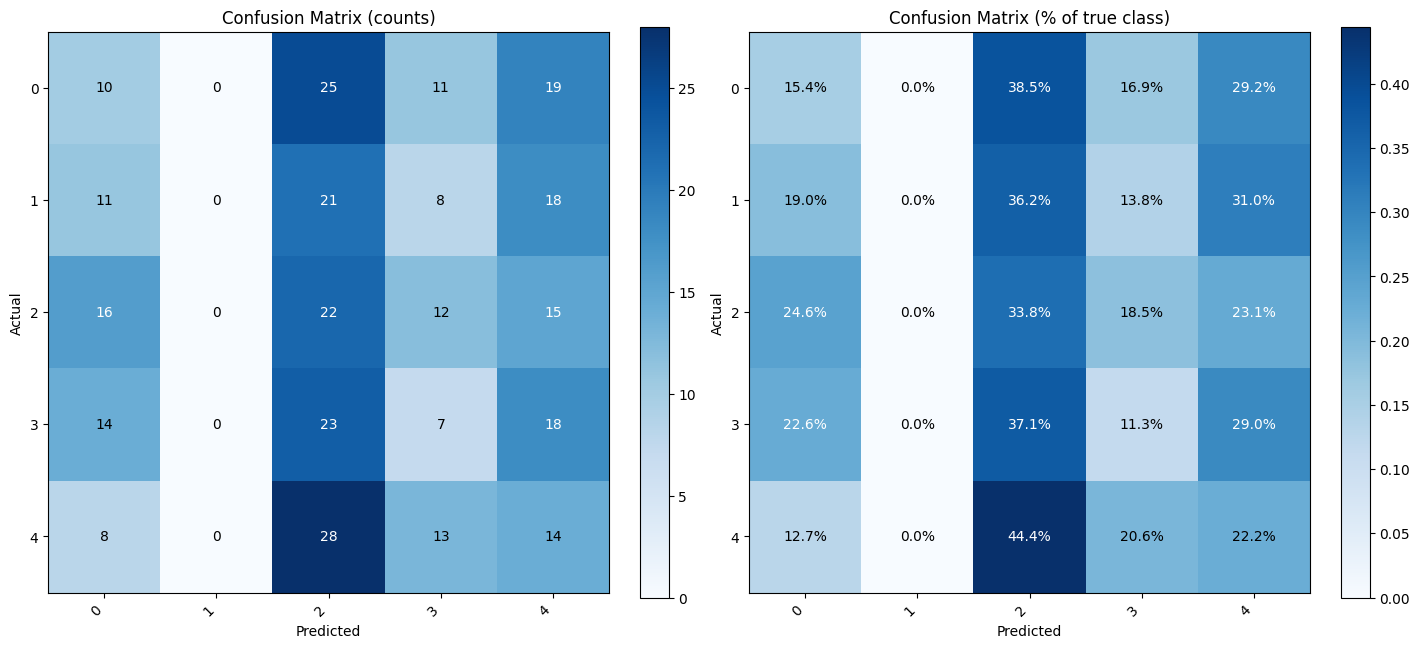

In [146]:
cm = plot_confusion_matrix(y_test, y_pred, labels=CLASSES)

## ROC and Precision-Recall Curves (one-vs-rest)

One curve per class: that class against all the others.

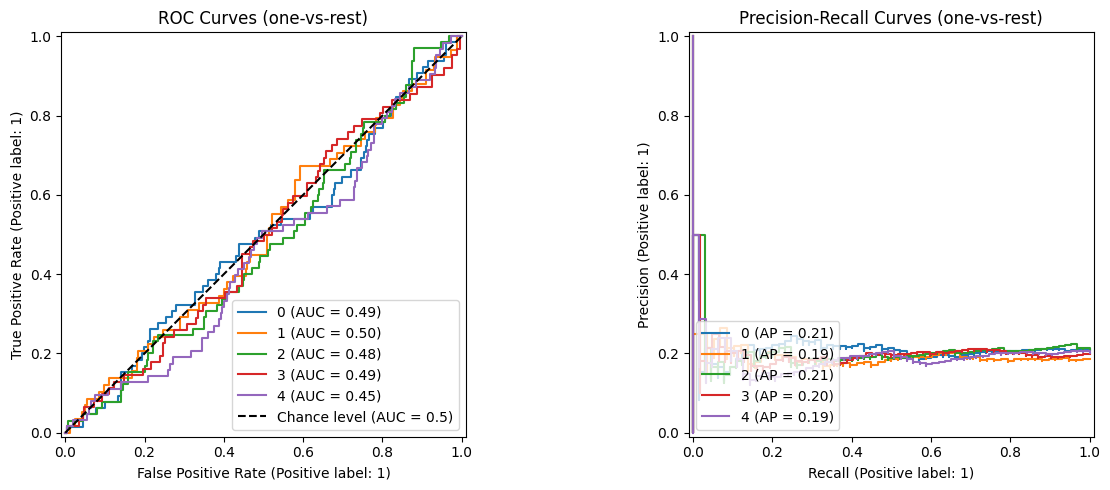

In [147]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for k, cls in enumerate(CLASSES):
    is_cls = (y_test == cls).to_numpy()
    RocCurveDisplay.from_predictions(is_cls, y_prob[:, k], ax=axes[0], name=str(cls),
                                     plot_chance_level=(k == len(CLASSES) - 1))
    PrecisionRecallDisplay.from_predictions(is_cls, y_prob[:, k], ax=axes[1], name=str(cls))
axes[0].set_title("ROC Curves (one-vs-rest)")
axes[1].set_title("Precision-Recall Curves (one-vs-rest)")
plt.tight_layout()
plt.show()

## Prediction Confidence

A binary model has one decision threshold to tune; a single-label multiclass model doesn't, since it predicts the class with the highest probability. Instead, check how confident those predictions are. If the model is well calibrated, accuracy should rise with confidence, and low-confidence rows are the ones to review or route elsewhere.

The bucket edges start at chance level (`1 / n_classes`), the lowest possible top probability.

In [148]:
confidence = y_prob.max(axis=1)
correct = (y_pred == y_test.to_numpy())

edges = np.linspace(1 / len(CLASSES), 1.0, 6)
buckets = pd.cut(confidence, bins=edges, include_lowest=True)
by_confidence = (
    pd.DataFrame({"bucket": buckets, "correct": correct})
    .groupby("bucket", observed=False)["correct"]
    .agg(rows="size", accuracy="mean")
    .round(3)
)
print(f"Mean top-class probability: {confidence.mean():.3f}")
by_confidence

Mean top-class probability: 0.229


,rows,accuracy
bucket,,
"(0.199, 0.36]",313,0.169
"(0.36, 0.52]",0,NaN
"(0.52, 0.68]",0,NaN
"(0.68, 0.84]",0,NaN
"(0.84, 1.0]",0,NaN


# Feature Influence

The multinomial model has **one coefficient per feature per class**. Coefficients are on the scaled features, so they are comparable to each other.
- A positive coefficient for a class means higher values of that feature push predictions toward that class; negative pushes away.
- `exp(coefficient)` scales the odds of that class (relative to the others) per one standard deviation of the feature.
- Read the table column by column (per class) rather than across.

In [149]:
coef_table = pd.DataFrame(model[-1].coef_.T, index=FEATURES, columns=[str(c) for c in CLASSES]).round(3)
coef_table["max_abs"] = coef_table.abs().max(axis=1)
coef_table.sort_values("max_abs", ascending=False)

,0,1,2,3,4,max_abs
sentiment_score,0.052,-0.032,0.122,-0.071,-0.071,0.122
emotion_score,0.024,0.015,-0.075,0.048,-0.012,0.075
quality_flag_encoded,-0.022,-0.011,0.041,0.001,-0.009,0.041
complexity_level_encoded,0.019,-0.027,0.005,0.013,-0.011,0.027


In [150]:
# Top features per class
TOP_N = 3
for cls in coef_table.columns.drop("max_abs"):
    top = coef_table[cls].sort_values(key=abs, ascending=False).head(TOP_N)
    print(f"{cls}: " + ", ".join(f"{f} ({v:+.2f})" for f, v in top.items()))

0: sentiment_score (+0.05), emotion_score (+0.02), quality_flag_encoded (-0.02)
1: sentiment_score (-0.03), complexity_level_encoded (-0.03), emotion_score (+0.01)
2: sentiment_score (+0.12), emotion_score (-0.07), quality_flag_encoded (+0.04)
3: sentiment_score (-0.07), emotion_score (+0.05), complexity_level_encoded (+0.01)
4: sentiment_score (-0.07), emotion_score (-0.01), complexity_level_encoded (-0.01)


# Sample Predictions (readable labels)

A few random test rows, with the actual and predicted class turned back into the original `domain_context` text via `TARGET_LABELS` (through `to_labels`). The original feature values are pulled from the raw dataset by row index, so each row reads in its source terms.

- **correct**: whether the predicted label matches the actual one.
- **confidence**: the model's probability for the predicted class.
- **prob: \<label\>**: the full probability spread across classes, to see near misses.

In [151]:
N_SAMPLES: int = 10

sample_idx = X_test.sample(n=min(N_SAMPLES, len(X_test)), random_state=RANDOM_STATE).index
X_sample = X_test.loc[sample_idx]

sample_pred = model.predict(X_sample)
sample_prob = model.predict_proba(X_sample)

# Original (pre-encoding) feature values, matched by row index
raw_df = load_dataset(DATA_FILE)
raw_features = raw_df.loc[sample_idx, [c for c in KEEP_COLS if c != "domain_context"]]

samples = raw_features.assign(
    actual=to_labels(y_test.loc[sample_idx]),
    predicted=to_labels(sample_pred),
    confidence=sample_prob.max(axis=1).round(3),
)
samples["correct"] = samples["actual"] == samples["predicted"]

prob_cols = pd.DataFrame(
    sample_prob.round(3), index=sample_idx, columns=[f"prob: {label}" for label in to_labels(CLASSES)]
)
samples = samples.join(prob_cols)

print(f"{samples['correct'].sum()}/{len(samples)} correct in this sample")
samples

1/10 correct in this sample


,complexity_level,quality_flag,actual,predicted,confidence,correct,prob: AI,prob: Climate,prob: Education,prob: NLP,prob: Translation
667,Medium,Low,Translation,Education,0.262,False,0.225,0.167,0.262,0.170,0.177
373,Medium,Low,NLP,Translation,0.211,False,0.205,0.184,0.192,0.208,0.211
955,Low,Low,Education,Education,0.237,True,0.218,0.182,0.237,0.178,0.186
144,Low,Low,NLP,Translation,0.208,False,0.202,0.190,0.207,0.193,0.208
1146,Medium,High,Translation,AI,0.230,False,0.230,0.179,0.210,0.192,0.190
1516,Medium,Low,AI,Translation,0.223,False,0.194,0.186,0.186,0.211,0.223
1541,Low,Medium,NLP,Translation,0.215,False,0.192,0.195,0.186,0.212,0.215
1494,Medium,High,AI,Translation,0.210,False,0.209,0.181,0.209,0.192,0.210
434,Medium,High,NLP,Translation,0.228,False,0.197,0.190,0.168,0.217,0.228
1369,Low,High,Climate,Translation,0.215,False,0.205,0.197,0.179,0.204,0.215


# Next Steps

- TODO